In [2]:
# Imports
import pandas as pd
import seaborn as sns
import pickle
import settings

from sklearn.model_selection import train_test_split
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, max_error, mean_absolute_percentage_error

climate_data = pd.read_csv(settings.TRAINING_DATA_PATH)


In [3]:
# Get idea about dataset
climate_data.shape


(1107, 11)

In [34]:
# Get idea about dataset
climate_data.describe()

,t_inside,h_inside,t_outside,h_outside,prev_t_inside,prev_h_inside,prev_t_outside,prev_h_outside,fanTargetSpeed
count,692.000000,692.000000,692.000000,692.000000,692.000000,692.000000,692.000000,692.000000,692.000000
mean,19.213584,51.898699,19.558815,48.866619,19.214740,51.897399,19.560549,48.862861,63.156069
std,0.655172,1.222621,0.792472,1.228755,0.655412,1.220540,0.794530,1.229825,21.938051
min,17.100000,48.000000,18.500000,44.700001,17.100000,48.000000,18.500000,44.700001,0.000000
25%,18.700001,51.099998,19.000000,48.175000,18.700001,51.099998,19.000000,48.099998,44.000000
50%,19.100000,51.799999,19.299999,48.799999,19.100000,51.799999,19.299999,48.799999,64.000000
75%,19.500000,52.400002,19.824999,49.400002,19.500000,52.400002,19.824999,49.400002,83.000000
max,21.000000,56.500000,21.600000,53.000000,21.000000,56.500000,21.600000,53.000000,99.000000


In [35]:
# Prepare data (defining x and y)
climate_data['Heating'] = climate_data['Heating'].astype(bool)
inputSet = climate_data.drop(columns=['t_inside', 'h_inside', 'timestamp'])
outputSet = climate_data[['t_inside', 'h_inside']]

In [36]:
# Splitting Data into train- and testdata
input_train, input_test, output_train, output_test = train_test_split(inputSet, outputSet, test_size=0.2)
input_train.shape, output_train.shape, input_test.shape, output_test.shape

((553, 8), (553, 2), (139, 8), (139, 2))

In [37]:
# Create Model
model = linear_model.LinearRegression()
model.fit(input_train, output_train)

LinearRegression()

In [46]:
# Make Predictions
test_predictions = model.predict(input_test)

In [75]:
# Model Performance

model_mse = mean_squared_error(output_test, test_predictions)
model_r2_score = r2_score(output_test, test_predictions)
model_mea = mean_absolute_error(output_test, test_predictions)
model_mape = mean_absolute_percentage_error(output_test, test_predictions)
score = model.score(input_test, output_test)

output_test_t_inside = output_test["t_inside"].to_list()
output_test_h_inside = output_test["h_inside"].to_list()
test_predictions_t_inside = test_predictions[:,0]
test_predictions_h_inside = test_predictions[:,1]

model_mea_t = mean_absolute_error(output_test_t_inside, test_predictions_t_inside)
model_mea_h = mean_absolute_error(output_test_h_inside, test_predictions_h_inside)

max_error_t = max_error(output_test_t_inside, test_predictions_t_inside)
max_error_h = max_error(output_test_h_inside, test_predictions_h_inside)


print("Score: ", score)
print("Coefficients: ", model.coef_)
print("Intercept: ", model.intercept_)
print("Mean squared error (MSE): ", model_mse)
print("Coefficient of determination (R^2): ", model_r2_score)
print("Mean Absolute error (MEA): ", model_mea)
print("Mean absolut percentage error (MAPE): ", model_mape)
print("Mean Absolute error temperature(MEA): ", model_mea_t)
print("Mean Absolute error humidity(MEA): ", model_mea_h)
print("Max Error Temperature: ", max_error_t)
print("Max Error Humidity: ", max_error_h)



Score:  0.9454844365060948
Coefficients:  [[ 6.70485976e-01 -7.58630278e-02  7.02205264e-01 -2.07817687e-02
  -4.00600876e-01  1.04884886e-01 -2.76825338e-04 -7.95114888e-03]
 [ 3.11740017e-01  6.69379821e-01 -1.37311078e+00  3.60945434e-01
   1.43806676e+00  5.73728836e-03  5.52533273e-04  3.44346783e-02]]
Intercept:  [ 0.12161924 -7.71905629]
Mean squared error (MSE):  0.05054117473236094
Coefficient of determination (R^2):  0.9454844365060948
Mean Absolute error (MEA):  0.12942377077466483
Mean absolut percentage error (MAPE):  0.0039729600839517815
Mean Absolute error temperature(MEA):  0.08921218546823141
Mean Absolute error humidity(MEA):  0.16963535608109823
Max Error Temperature:  1.05931834666956
Max Error Humidity:  2.423884284233864


In [9]:
model.predict([[20.10000038, 49.5, 19.10000038, 54.29999924, 20, 49.59999847, 32, False]])


array([[19.31014544, 54.1369786 ]])

<AxesSubplot:xlabel='t_inside'>

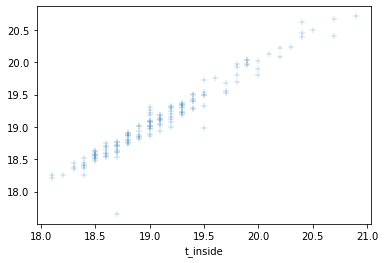

In [10]:
# Create Plots


test_t = output_test["t_inside"]
test_h = output_test["h_inside"]
predicted_t = test_predictions[:,0]
predicted_h = test_predictions[:,1]

# temperature
sns.scatterplot(x = test_t, y = predicted_t, marker="+", alpha=0.5 )

<AxesSubplot:xlabel='h_inside'>

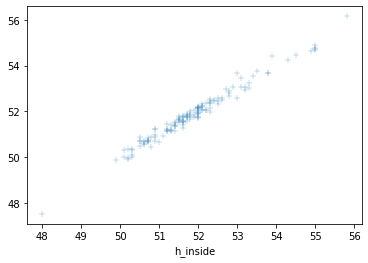

In [82]:
# humidity
sns.scatterplot(x=test_h, y = predicted_h, marker="+", alpha=0.5)

In [11]:
# Save to file in the current working directory
pkl_filename = settings.TRAINED_MODEL_PATH
with open(pkl_filename, 'wb') as file:
    pickle.dump(model, file)
